In [2]:
import rasterio
from rasterio.enums import Resampling
from rasterio.warp import calculate_default_transform, reproject
from rasterio.transform import from_origin
import numpy as np
import geopandas as gpd
from shapely.geometry import Point
from shapely.geometry import box
import random
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from scipy.stats import pearsonr
from sklearn.metrics import r2_score
import pandas as pd
import numpy as np
import rioxarray as rxr

c:\Users\minyu\.conda\envs\ICESAT_env\lib\site-packages\cupy\_environment.py:215: UserWarning: CUDA path could not be detected. Set CUDA_PATH environment variable if CuPy fails to load.
  warnings.warn(


In [2]:
Henber_point_path = 'E:\FB_download9\FB_importance\Henber_2019_sample_points_final_new.shp'
Morecambe_point_path = 'E:\FB_download9\FB_importance\Morecambe_2023_sample_points_final_new.shp'
Ribble_point_path = 'E:\FB_download9\FB_importance\Ribble1_2021_sample_points_final_new.shp'
Dee_point_path = 'E:\FB_download9\FB_importance\Ribble_2019_sample_points_new.shp'
Severn_point_path = 'E:\FB_download9\FB_importance\Severn_2020_sample_points_new.shp'
Solway_point_path = 'E:\FB_download9\FB_importance\Solway_2023_sample_points_final_new.shp'
Thames_point_path= 'E:\FB_download9\FB_importance\Thames1_2019_sample_points_final_new.shp'
Wash_point_path = 'E:\FB_download9\FB_importance\wash_bay_2022_sample_points_final_new.shp'

point_list = [Henber_point_path, Morecambe_point_path, Ribble_point_path, Dee_point_path, Severn_point_path, 
              Solway_point_path, Thames_point_path, Wash_point_path]


In [4]:
k = gpd.read_file(Wash_point_path)
k.shape[0]
a =0
for path in point_list:
    
    k = gpd.read_file(path)
    a += k.shape[0]

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# 示例数据
x = np.array(k['Refer_dem'])
y = np.array(k['b9_T'])

# 计算 Pearson 相关系数和 p 值
corr, p_value = pearsonr(x, y)

# 绘制散点图
plt.figure(figsize=(5, 5))
plt.scatter(x, y, color='dodgerblue', edgecolor='black', s=10)
plt.title(f"Scatter Plot\nPearson Correlation = {corr:.2f}", fontsize=14)
plt.xlabel("X")
plt.ylabel("Y")

# 可选：添加趋势线（线性拟合）
m, b = np.polyfit(x, y, 1)
plt.plot(x, m*x + b, color='red', linestyle='--', label='Linear Fit')
plt.legend()

plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:

k = gpd.read_file(Wash_point_path)
k = k[k['DTM_B1']!=0]
x = np.array(k['Refer_dem'])
y = np.array(k['Freq'])
# y = np.array(k['DTM_B5'])
R, _ = pearsonr(y, x)
R2 = r2_score(x, y)
MAD = np.mean(np.abs(y-x))
MSB = np.mean((y-x))
RMSE = np.sqrt(np.mean((y-x)**2))
num = int(len(x))


xy = np.vstack([x,y])  #  将两个维度的数据叠加
z = gaussian_kde(xy)(xy)  # 建立概率密度分布，并计算每个样本点的概率密度

# Sort the points by density, so that the densest points are plotted last
idx = z.argsort()
x, y, z = x[idx], y[idx], z[idx]

fig, ax = plt.subplots()
textstr = f"R2 = {R:.3f}\nMAE = {MAD:.3f}\nRMSE = {RMSE:.3f} \nN = {num}"
textstr = f"R = {R:.3f} \nN = {num}"
# name = f'{'Wash'} ({year})'
name = f'wash__2022'
ax.text(0.05, 0.95, textstr, transform = ax.transAxes, fontsize = 16, verticalalignment = 'top')
ax.text(0.95, 0.05, name, transform=ax.transAxes, fontsize=16, verticalalignment='bottom', horizontalalignment='right')

ax.set_xlabel('Reference dem', fontsize = 15)
ax.set_ylabel('Retrieved dem', fontsize = 15)
# ax.plot([0, 0.1], [-3, 4], color='gray', linestyle='--', linewidth=0.8, zorder=1)
sc = plt.scatter(y, x, c=z, s=5, cmap='Spectral_r', zorder=2)
cbar = plt.colorbar(sc)

# plt.scatter(x, y,c=z, s=2,cm[-3, 4], ap='Spectral_r') # c表示标记的颜色
# plt.colorbar()

# ax.set_xlim(-3, 4)
ax.set_ylim(-3, 4)
ax.tick_params(axis='both', labelsize=12)
# output_path = f"G:\ICESat-2\Discussion5_2\graph/wash_{obs_num}_Freq_2022.png"  # 例如："./output/plot.png"
# plt.savefig(output_path, dpi=300, bbox_inches='tight') 
plt.show()

In [66]:
k = gpd.read_file(Wash_point_path)
k.columns

Index(['Refer_dem', 'NEF_S2_L89', 'NEF_S2', 'NEF_L89', 'B1_mean_S2',
       'B2_mean_S2', 'B3_mean_S2', 'B4_mean_S2', 'B5_mean_S2', 'B6_mean_S2',
       'B7_mean_S2', 'B8_mean_S2', 'B8A_mean_S', 'B11_mean_S', 'B12_mean_S',
       'NDWI_mean_', 'MNDWI_mean', 'NDWI_min_S', 'MNDWI_min_', 'B1_mean_L8',
       'B2_mean_L8', 'B3_mean_L8', 'B4_mean_L8', 'B5_mean_L8', 'B5_mean__1',
       'B6_mean_L8', 'B7_mean_L8', 'NDWI_mea_1', 'MNDWI_me_1', 'geometry'],
      dtype='object')

In [ ]:
k = gpd.read_file(Morecambe_point_path)
k1 = k[band_list]
b = gpd.read_file(Ribble_point_path)
b1 = k[band_list]
print(k1.shape)
c = pd.concat([k1, b1], axis=0)
c.shape

In [ ]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt

# 假设有 100 个样本，每个样本有 6 个波段特征
# Henber_point_path = 'G:\ICESat-2\FB_importance\Henber_2019_sample_points_final.shp'
# Morecambe_point_path = 'G:\ICESat-2\FB_importance\Morecambe_2019_sample_points_final.shp'
# Ribble_point_path = 'G:\ICESat-2\FB_importance\Ribble1_2021_sample_points_final.shp'
# Solway_point_path = 'G:\ICESat-2\FB_importance\Solway_2023_sample_points_final.shp'
# Thames_point_path= 'G:\ICESat-2\FB_importance\Thames1_2019_sample_points_final.shp'
# Wash_point_path = 'G:\ICESat-2\FB_importance\wash_bay_2022_sample_points_final.shp'
# list = [Henber_point_path, Morecambe_point_path, Ribble_point_path, Solway_point_path, Thames_point_path, Wash_point_path]
Henber_point_path = 'E:\FB_download9\FB_importance\Henber_2019_sample_points_final_new.shp'
Morecambe_point_path = 'E:\FB_download9\FB_importance\Morecambe_2023_sample_points_final_new.shp'
Ribble_point_path = 'E:\FB_download9\FB_importance\Ribble1_2021_sample_points_final_new.shp'
Dee_point_path = 'E:\FB_download9\FB_importance\Ribble_2019_sample_points_new.shp'
Severn_point_path = 'E:\FB_download9\FB_importance\Severn_2020_sample_points_new.shp'
Solway_point_path = 'E:\FB_download9\FB_importance\Solway_2023_sample_points_final_new.shp'
Thames_point_path= 'E:\FB_download9\FB_importance\Thames1_2019_sample_points_final_new.shp'
Wash_point_path = 'E:\FB_download9\FB_importance\wash_bay_2022_sample_points_final_new.shp'

point_list = [Henber_point_path, Morecambe_point_path, Ribble_point_path, Dee_point_path, Severn_point_path, 
              Solway_point_path, Thames_point_path, Wash_point_path]




# k = gpd.read_file(Morecambe_point_path)
# print(k.shape)
band_list = ['Refer_dem', 'NEF_S2_L89', 'NEF_S2', 'NEF_L89', 'B1_mean_S2',
       'B2_mean_S2', 'B3_mean_S2', 'B4_mean_S2', 'B5_mean_S2', 'B6_mean_S2',
       'B7_mean_S2', 'B8_mean_S2', 'B8A_mean_S', 'B11_mean_S', 'B12_mean_S',
       'NDWI_mean_', 'MNDWI_mean', 'NDWI_min_S', 'MNDWI_min_', 'B1_mean_L8',
       'B2_mean_L8', 'B3_mean_L8', 'B4_mean_L8', 'B5_mean_L8', 'B5_mean__1',
       'B6_mean_L8', 'B7_mean_L8', 'NDWI_mea_1', 'MNDWI_me_1']
empty = []
for i in range(8):
    k = gpd.read_file(point_list[i])
    k_fb = k[band_list]
    empty.append(k_fb)

collect = pd.concat(empty, axis=0)

# band_list1 = ['Freq','mean_B1' ,'mean_Blue', 'mean_Green', 'mean_MNDWI', 'mean_NDWI','mean_NIR', 'mean_RE1', 'mean_RE2', 'mean_RE3',
#              'mean_RE4','mean_Red', 'mean_SWIR1', 'mean_SWIR2', 'min_MNDWI', 'NDWI_min']

# band_list2 = ['Freq', 'mean_MNDWI', 'mean_RE4', 'mean_NIR','mean_RE3','mean_RE2',
#               'mean_MNDWI','mean_SR_B5','mean_SWIR1', 'mean_SWIR2','mean_SR_B6',
#               'mean_RE1','min_MNDWI', 'mean_SR_B7', 'mean_SR_B4', 'mean_Red',
#               'mean_SR_B1', 'mean_SR_B2', 'mean_SR_B3', 'mean_B1', 'mean_Green',
#               'mean_Blue', 'NDWI_min']

# df = k[band_list]#,'b2_T','b3_T','b4_T','b5_T','b6_T'
df = collect[band_list]
y = df['Refer_dem']

corrs = df.corr()['Refer_dem'].drop('Refer_dem')
selected = corrs.abs().sort_values(ascending=False)
print(selected)
print(len(selected))
# # 构建并训练模型
# clf = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=30)
# clf.fit(X, y)

# # 查看各特征重要性
# importances = clf.feature_importances_
# print(importances)
# # 可视化
# plt.figure(figsize=(8,4))
# plt.bar(X.columns, importances, color='skyblue', edgecolor='black')
# plt.title("Feature Importances")
# plt.ylabel("Importance")
# plt.xticks(rotation=45)
# plt.tight_layout()
# plt.show()


In [82]:
collect.columns

Index(['Refer_dem', 'NEF_S2_L89', 'NEF_S2', 'NEF_L89', 'B1_mean_S2',
       'B2_mean_S2', 'B3_mean_S2', 'B4_mean_S2', 'B5_mean_S2', 'B6_mean_S2',
       'B7_mean_S2', 'B8_mean_S2', 'B8A_mean_S', 'B11_mean_S', 'B12_mean_S',
       'NDWI_mean_', 'MNDWI_mean', 'NDWI_min_S', 'MNDWI_min_', 'B1_mean_L8',
       'B2_mean_L8', 'B3_mean_L8', 'B4_mean_L8', 'B5_mean_L8', 'B5_mean__1',
       'B6_mean_L8', 'B7_mean_L8', 'NDWI_mea_1', 'MNDWI_me_1'],
      dtype='object')

In [4]:
len(collect)

37604

In [5]:
Henber_point_path = 'E:\FB_download9\FB_importance\Henber_2019_sample_points_final_new.shp'
x = gpd.read_file(Henber_point_path)
x.columns

Index(['Refer_dem', 'NEF_S2_L89', 'NEF_S2', 'NEF_L89', 'B1_mean_S2',
       'B2_mean_S2', 'B3_mean_S2', 'B4_mean_S2', 'B5_mean_S2', 'B6_mean_S2',
       'B7_mean_S2', 'B8_mean_S2', 'B8A_mean_S', 'B11_mean_S', 'B12_mean_S',
       'NDWI_mean_', 'MNDWI_mean', 'NDWI_min_S', 'MNDWI_min_', 'B1_mean_L8',
       'B2_mean_L8', 'B3_mean_L8', 'B4_mean_L8', 'B5_mean_L8', 'B5_mean__1',
       'B6_mean_L8', 'B7_mean_L8', 'NDWI_mea_1', 'MNDWI_me_1', 'geometry'],
      dtype='object')

In [ ]:
# Henber_point_path = 'G:\ICESat-2\FB_importance\Henber_2019_sample_points_final.shp'
# Morecambe_point_path = 'G:\ICESat-2\FB_importance\Morecambe_2019_sample_points_final.shp'
# Ribble_point_path = 'G:\ICESat-2\FB_importance\Ribble1_2021_sample_points_final.shp'
# Solway_point_path = 'G:\ICESat-2\FB_importance\Solway_2023_sample_points_final.shp'
# Thames_point_path= 'G:\ICESat-2\FB_importance\Thames1_2019_sample_points_final.shp'
# Wash_point_path = 'G:\ICESat-2\FB_importance\wash_bay_2022_sample_points_final.shp'

# list = [Henber_point_path, Morecambe_point_path, Ribble_point_path, Solway_point_path, Thames_point_path, Wash_point_path]
band_list = ['Refer_dem','NEF_S2_L89', 'NEF_S2', 'NEF_L89', 'B1_mean_S2',
       'B2_mean_S2', 'B3_mean_S2', 'B4_mean_S2', 'B5_mean_S2', 'B6_mean_S2',
       'B7_mean_S2', 'B8_mean_S2', 'B8A_mean_S', 'B11_mean_S', 'B12_mean_S',
       'NDWI_mean_', 'MNDWI_mean', 'NDWI_min_S', 'MNDWI_min_', 'B1_mean_L8',
       'B2_mean_L8', 'B3_mean_L8', 'B4_mean_L8', 'B5_mean_L8', 'B5_mean__1',
       'B6_mean_L8', 'B7_mean_L8', 'NDWI_mea_1', 'MNDWI_me_1']

Henber_point_path = 'E:\FB_download9\FB_importance\Henber_2019_sample_points_final_new.shp'
Morecambe_point_path = 'E:\FB_download9\FB_importance\Morecambe_2023_sample_points_final_new.shp'
Ribble_point_path = 'E:\FB_download9\FB_importance\Ribble1_2021_sample_points_final_new.shp'
Dee_point_path = 'E:\FB_download9\FB_importance\Ribble_2019_sample_points_new.shp'
Severn_point_path = 'E:\FB_download9\FB_importance\Severn_2020_sample_points_new.shp'
Solway_point_path = 'E:\FB_download9\FB_importance\Solway_2023_sample_points_final_new.shp'
Thames_point_path= 'E:\FB_download9\FB_importance\Thames1_2019_sample_points_final_new.shp'
Wash_point_path = 'E:\FB_download9\FB_importance\wash_bay_2022_sample_points_final_new.shp'

point_list = [Henber_point_path, Morecambe_point_path, Ribble_point_path, Dee_point_path, Severn_point_path, 
              Solway_point_path, Thames_point_path, Wash_point_path]
null = []
all_points = []
for i in range(len(point_list)):
    
    path = point_list[i]
    k = gpd.read_file(path)
    
    # df = k[['b1_T','b2_T','b3_T','b4_T','b5_T','b6_T','b7_T','b8_T','b9_T','Refer_dem']]
    df = k[band_list]
    print(len(df))
    corrs = df.corr()['Refer_dem'].drop('Refer_dem')

    # 用绝对值排序
    selected = corrs.abs()
    # print(selected)
    null.append(selected)
    
    

2630
10565
2301
4784
2909
1991
6202
6222


In [18]:
import geopandas as gpd
import pandas as pd

# 河口shapefile路径列表
all_point_paths = [
    r'E:\FB_download9\FB_importance\Henber_2019_sample_points_final_new.shp',
    r'E:\FB_download9\FB_importance\Morecambe_2023_sample_points_final_new.shp',
    r'E:\FB_download9\FB_importance\Ribble1_2021_sample_points_final_new.shp',
    r'E:\FB_download9\FB_importance\Ribble_2019_sample_points_new.shp',  # Dee
    r'E:\FB_download9\FB_importance\Severn_2020_sample_points_new.shp',
    r'E:\FB_download9\FB_importance\Solway_2023_sample_points_final_new.shp',
    r'E:\FB_download9\FB_importance\Thames1_2019_sample_points_final_new.shp',
    r'E:\FB_download9\FB_importance\wash_bay_2022_sample_points_final_new.shp'
]

# 河口名称
estuary_names = ['Henber', 'Morecambe', 'Ribble1', 'Dee', 'Severn', 'Solway', 'Thames', 'Wash']

# 统一的band_list字段
band_list = ['Refer_dem','NEF_S2_L89', 'NEF_S2', 'NEF_L89', 'B1_mean_S2',
             'B2_mean_S2', 'B3_mean_S2', 'B4_mean_S2', 'B5_mean_S2', 'B6_mean_S2',
             'B7_mean_S2', 'B8_mean_S2', 'B8A_mean_S', 'B11_mean_S', 'B12_mean_S',
             'NDWI_mean_', 'MNDWI_mean', 'NDWI_min_S', 'MNDWI_min_', 'B1_mean_L8',
             'B2_mean_L8', 'B3_mean_L8', 'B4_mean_L8', 'B5_mean_L8', 'B5_mean__1',
             'B6_mean_L8', 'B7_mean_L8', 'NDWI_mea_1', 'MNDWI_me_1']

# 用于存放每个河口数据的列表
df_list = []

for path, name in zip(all_point_paths, estuary_names):
    gdf = gpd.read_file(path)
    # 检查band_list哪些字段在shapefile中存在
    available_bands = [b for b in band_list if b in gdf.columns]
    # 提取这些字段
    temp_df = gdf[available_bands].copy()
    temp_df['Estuary'] = name  # 添加河口列
    df_list.append(temp_df)

# 合并所有河口数据
merged_df = pd.concat(df_list, ignore_index=True)

# 查看结果
merged_df.columns


Index(['Refer_dem', 'NEF_S2_L89', 'NEF_S2', 'NEF_L89', 'B1_mean_S2',
       'B2_mean_S2', 'B3_mean_S2', 'B4_mean_S2', 'B5_mean_S2', 'B6_mean_S2',
       'B7_mean_S2', 'B8_mean_S2', 'B8A_mean_S', 'B11_mean_S', 'B12_mean_S',
       'NDWI_mean_', 'MNDWI_mean', 'NDWI_min_S', 'MNDWI_min_', 'B1_mean_L8',
       'B2_mean_L8', 'B3_mean_L8', 'B4_mean_L8', 'B5_mean_L8', 'B5_mean__1',
       'B6_mean_L8', 'B7_mean_L8', 'NDWI_mea_1', 'MNDWI_me_1', 'Estuary'],
      dtype='object')

37604


(array([0.5, 1.5, 2.5, 3.5, 4.5, 5.5, 6.5]),
 [Text(0, 0.5, 'NAEF_S2_L89'),
  Text(0, 1.5, 'NDWI_mean'),
  Text(0, 2.5, 'MNDWI_mean'),
  Text(0, 3.5, 'B8A_mean_S2'),
  Text(0, 4.5, 'B8_mean_S2'),
  Text(0, 5.5, 'B7_mean_S2'),
  Text(0, 6.5, 'B6_mean_S2')])

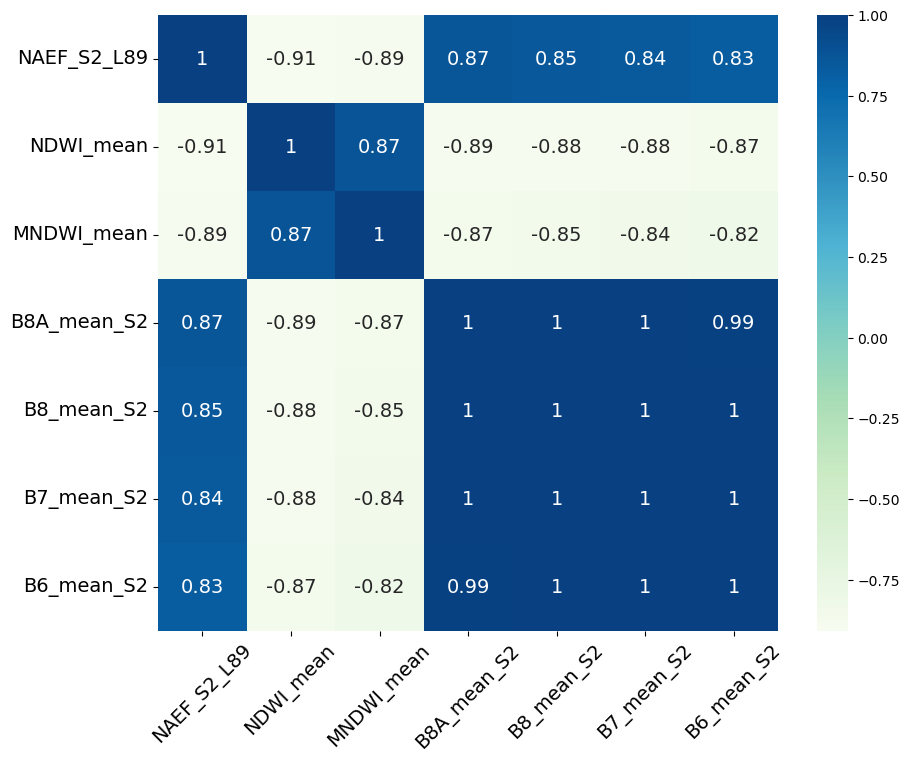

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt
bands_list = ['NEF_S2_L89', 'NDWI_mean_', 'MNDWI_mean', 'B8A_mean_S','B8_mean_S2', 'B7_mean_S2','B6_mean_S2']
Bands_name = ['NAEF_S2_L89', 'NDWI_mean', 'MNDWI_mean', 'B8A_mean_S2','B8_mean_S2', 'B7_mean_S2','B6_mean_S2']
print(len(merged_df))
corr = pd.DataFrame(merged_df[bands_list]).corr()
plt.figure(figsize=(10, 8))
# sns.heatmap(corr, annot=True, cmap='coolwarm')
sns.heatmap(corr, annot=True, cmap='GnBu',
            xticklabels=Bands_name,
            yticklabels=Bands_name, annot_kws={"size": 14})
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xticks(rotation=45)  # 如果名字太长可以旋转
plt.yticks(rotation=0)
# plt.xlabel("Features", fontsize=14)
# plt.ylabel("Features", fontsize=14)

In [7]:
l = np.array(null)

std = np.std(l, axis=0)
print(std)
mean = np.mean(l, axis=0)
print(mean)

[0.0235878  0.02347565 0.05771739 0.16497318 0.15105963 0.13765121
 0.18807778 0.13680123 0.04783793 0.04932053 0.0442174  0.03427082
 0.08444784 0.08551496 0.04413875 0.09792737 0.12416302 0.13847935
 0.09681436 0.11077874 0.13542244 0.14095127 0.04787157 0.04787157
 0.07783517 0.08047956 0.22177518 0.19577065]
[0.94688024 0.94468599 0.86418915 0.28250294 0.28943407 0.35151387
 0.47696336 0.64940385 0.81030481 0.8175081  0.82899828 0.84525706
 0.77997227 0.73335519 0.90278682 0.86385073 0.40075116 0.70138301
 0.60662489 0.59844807 0.58410303 0.6344679  0.83247855 0.83247855
 0.7478752  0.70373392 0.30043828 0.59552141]


In [14]:
import numpy as np


order = np.argsort(-mean)

# band order
x = np.array(['NEF_S2_L89', 'NEF_S2', 'NEF_L89', 'B1_mean_S2',
       'B2_mean_S2', 'B3_mean_S2', 'B4_mean_S2', 'B5_mean_S2', 'B6_mean_S2',
       'B7_mean_S2', 'B8_mean_S2', 'B8A_mean_S', 'B11_mean_S', 'B12_mean_S',
       'NDWI_mean_', 'MNDWI_mean', 'NDWI_min_S', 'MNDWI_min_', 'B1_mean_L8',
       'B2_mean_L8', 'B3_mean_L8', 'B4_mean_L8', 'B5_mean_L8', 'B5_mean__1',
       'B6_mean_L8', 'B7_mean_L8', 'NDWI_mea_1', 'MNDWI_me_1'])


# 应用排序顺序
mean_sorted = mean[order]
std_sorted = std[order]
x_order = x[order]
print("排序后的 mean:", mean_sorted)
print("排序后的 std:", std_sorted)
print("排序后的 std:", x_order)


排序后的 mean: [0.94688024 0.94468599 0.90278682 0.86418915 0.86385073 0.84525706
 0.83247855 0.83247855 0.82899828 0.8175081  0.81030481 0.77997227
 0.7478752  0.73335519 0.70373392 0.70138301 0.64940385 0.6344679
 0.60662489 0.59844807 0.59552141 0.58410303 0.47696336 0.40075116
 0.35151387 0.30043828 0.28943407 0.28250294]
排序后的 std: [0.0235878  0.02347565 0.04413875 0.05771739 0.09792737 0.03427082
 0.04787157 0.04787157 0.0442174  0.04932053 0.04783793 0.08444784
 0.07783517 0.08551496 0.08047956 0.13847935 0.13680123 0.14095127
 0.09681436 0.11077874 0.19577065 0.13542244 0.18807778 0.12416302
 0.13765121 0.22177518 0.15105963 0.16497318]
排序后的 std: ['NEF_S2_L89' 'NEF_S2' 'NDWI_mean_' 'NEF_L89' 'MNDWI_mean' 'B8A_mean_S'
 'B5_mean__1' 'B5_mean_L8' 'B8_mean_S2' 'B7_mean_S2' 'B6_mean_S2'
 'B11_mean_S' 'B6_mean_L8' 'B12_mean_S' 'B7_mean_L8' 'MNDWI_min_'
 'B5_mean_S2' 'B4_mean_L8' 'B1_mean_L8' 'B2_mean_L8' 'MNDWI_me_1'
 'B3_mean_L8' 'B4_mean_S2' 'NDWI_min_S' 'B3_mean_S2' 'NDWI_mea_1'
 'B2_m

In [9]:
x_order

array(['NEF_S2_L89', 'NEF_S2', 'NDWI_mean_', 'NEF_L89', 'MNDWI_mean',
       'B8A_mean_S', 'B5_mean__1', 'B5_mean_L8', 'B8_mean_S2',
       'B7_mean_S2', 'B6_mean_S2', 'B11_mean_S', 'B6_mean_L8',
       'B12_mean_S', 'B7_mean_L8', 'MNDWI_min_', 'B5_mean_S2',
       'B4_mean_L8', 'B1_mean_L8', 'B2_mean_L8', 'MNDWI_me_1',
       'B3_mean_L8', 'B4_mean_S2', 'NDWI_min_S', 'B3_mean_S2',
       'NDWI_mea_1', 'B2_mean_S2', 'B1_mean_S2'], dtype='<U10')

In [ ]:
fig, ax = plt.subplots(figsize=(10, 3))


mean_sorted = [0.94688024, 0.94468599, 0.86418915,
               0.90278682,  0.86385073, 0.84525706,
        0.82899828, 0.8175081 ,0.81030481, 
       0.7947855, 0.77997227,   0.7478752 , 0.73335519, 0.70373392,
       0.70138301, 0.64940385, 0.6344679 , 0.60662489,
       0.59552141, 0.58410303, 0.47696336, 0.40075116, 0.35151387,
        0.28943407, 0.28250294]

std_sorted = [0.0235878 , 0.02347565,  0.05771739,
               0.04413875, 0.09792737, 0.03427082,
      0.0442174 , 0.04932053, 0.04783793,
       0.04787157, 0.08444784,  0.07783517, 0.08551496, 0.08047956,
       0.13847935, 0.13680123, 0.14095127, 0.09681436, 
       0.19577065, 0.13542244, 0.18807778, 0.12416302, 0.13765121,
        0.15105963, 0.16497318]

x_order = ['NAEF_S2_L89', 'NAEF_S2', 'NAEF_L89', 
           'NDWI_mean', 'MNDWI_mean','B8A_mean_S2',
           'B8_mean_S2','B7_mean_S2','B6_mean_S2', 
           'B5_mean_L8','B11_mean_S2', 'B6_mean_L8','B12_mean_S','B7_mean_L8',
           'MNDWI_min_S2','B5_mean_S2', 'B4_mean_L8', 'B1_mean_L8',
           'B2_mean_L8', 'B3_mean_L8', 'B4_mean_S2', 'NDWI_min_S2', 'B3_mean_S2',
           'B2_mean_S2', 'B1_mean_S2']


# for i in range(len(x_order)):
#     color = "#D62728" if (i==0) |(i==3)|(i==4)|(i==5)  else ( "#EABFA0" if (i==1)|(i==2)|(i==6)|(i==7)|(i==8) else "#656262" )#
#     ax.errorbar(x_order[i], mean_sorted[i], yerr=std_sorted[i], fmt='D', color=color, ecolor=color,
#                 capsize=8, elinewidth=2, linewidth=4)

# # 添加 0.8 的参考线
# ax.axhline(y=0.8, color='#D62728', linestyle='--', linewidth=1.5)

# ax.grid(axis='x', linestyle='--', alpha=1)
# ax.grid(axis='y', linestyle='--', alpha=1)
# ax.set_ylim(0, 1)
# ax.tick_params(axis='both', labelsize=12)

# plt.xticks(rotation=80)
# ax.set_ylabel('Absolute Pearson R', fontsize=12)

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 3))

# ===== 添加前三个灰色背景 =====
for i in range(3):
    ax.axvspan(i - 0.4, i + 0.4, color='#E8E8E8', alpha=0.8, zorder=0)

# 绘制误差棒
for i in range(len(x_order)):
    color = (
        "#D62728" if (i==0) |(i==3)|(i==4)|(i==5) else
        "#EABFA0" if (i==1)|(i==2)|(i==6)|(i==7)|(i==8) else
        "#656262"
    )
    ax.errorbar(x_order[i], mean_sorted[i], yerr=std_sorted[i],
                fmt='D', color=color, ecolor=color, capsize=8, elinewidth=2, linewidth=4, zorder=2)

# 参考线
ax.axhline(y=0.8, color='#D62728', linestyle='--', linewidth=1.5)

# 网格与样式
ax.grid(axis='x', linestyle='--', alpha=1)
ax.grid(axis='y', linestyle='--', alpha=1)
ax.set_ylim(0, 1)
ax.tick_params(axis='both', labelsize=12)
plt.xticks(rotation=80)
ax.set_ylabel('Absolute Pearson R', fontsize=12)

# ===== 缩小前后边距 =====
# plt.subplots_adjust(left=0.08, right=0.98, bottom=0.3, top=0.95)

plt.show()

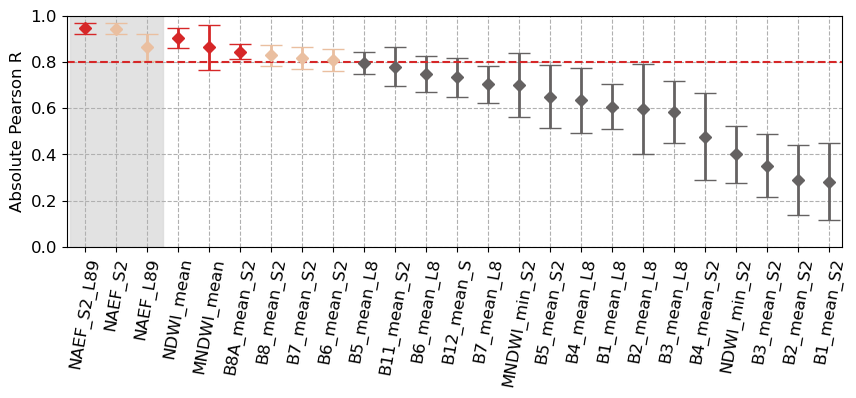

In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 3))

mean_sorted = [0.94688024, 0.94468599, 0.86418915, 0.90278682, 0.86385073, 0.84525706, 0.82899828, 0.8175081 ,0.81030481, 0.7947855, 0.77997227, 0.7478752 , 0.73335519, 0.70373392, 0.70138301, 0.64940385, 0.6344679 , 0.60662489, 0.59552141, 0.58410303, 0.47696336, 0.40075116, 0.35151387, 0.28943407, 0.28250294]
std_sorted  = [0.0235878 , 0.02347565, 0.05771739, 0.04413875, 0.09792737, 0.03427082, 0.0442174 , 0.04932053, 0.04783793, 0.04787157, 0.08444784, 0.07783517, 0.08551496, 0.08047956, 0.13847935, 0.13680123, 0.14095127, 0.09681436, 0.19577065, 0.13542244, 0.18807778, 0.12416302, 0.13765121, 0.15105963, 0.16497318]
x_order = ['NAEF_S2_L89', 'NAEF_S2', 'NAEF_L89', 'NDWI_mean', 'MNDWI_mean','B8A_mean_S2', 'B8_mean_S2','B7_mean_S2','B6_mean_S2', 'B5_mean_L8','B11_mean_S2', 'B6_mean_L8','B12_mean_S','B7_mean_L8', 'MNDWI_min_S2','B5_mean_S2', 'B4_mean_L8', 'B1_mean_L8', 'B2_mean_L8', 'B3_mean_L8', 'B4_mean_S2', 'NDWI_min_S2', 'B3_mean_S2', 'B2_mean_S2', 'B1_mean_S2']

# 连续的灰色背景（前三个）
ax.axvspan(-0.5, 2.5, color="#DBDBDBCB", alpha=0.8, zorder=0)

# 绘制误差棒
for i in range(len(x_order)):
    color = (
        "#D62728" if (i==0) |(i==3)|(i==4)|(i==5) else
        "#EABFA0" if (i==1)|(i==2)|(i==6)|(i==7)|(i==8) else
        "#656262"
    )
    ax.errorbar(x_order[i], mean_sorted[i], yerr=std_sorted[i],
                fmt='D', color=color, ecolor=color, capsize=8, elinewidth=2, linewidth=4, zorder=2)

# 添加参考线
ax.axhline(y=0.8, color='#D62728', linestyle='--', linewidth=1.5)

# 网格与样式
ax.grid(axis='x', linestyle='--', alpha=1)
ax.grid(axis='y', linestyle='--', alpha=1)
ax.set_ylim(0, 1)
ax.tick_params(axis='both', labelsize=12)
plt.xticks(rotation=80)
ax.set_ylabel('Absolute Pearson R', fontsize=12)

# 🔹仅通过限制x轴范围来去掉左右空白（不改变比例）
ax.set_xlim(-0.6, len(x_order) - 0.6)

# 🔹保持整体布局比例，仅稍微收紧外边距（不影响形状）
# plt.subplots_adjust(left=0.06, right=0.99, bottom=0.3, top=0.95)

plt.show()


In [10]:
Wash_point_path = 'G:\ICESat-2\FB_importance\wash_bay_2022_sample_points_final.shp'
Morecambe_point_path = 'G:\ICESat-2\FB_importance\Morecambe_2019_sample_points_final.shp'
Thames_point_path= 'G:\ICESat-2\FB_importance\Thames1_2019_sample_points_final.shp'
k = gpd.read_file(Thames_point_path)
k = k[k['DTM_B1']!=0]
null = []
for i in range(8):
    
    
    x = np.array(k['Refer_dem'])
    y = np.array(k[f'DTM_B{i+1}'])
    R, _ = pearsonr(y, x)
    R2 = r2_score(x, y)
    # MAD = np.mean(np.abs(y-x))
    # MSB = np.mean((y-x))
    RMSE = np.sqrt(np.mean((y-x)**2))
    print('R2:', R2, ' RMSE:', RMSE)
    # num = int(len(x))


R2: 0.4625914937922103  RMSE: 0.5892453981221452
R2: 0.4453594608830146  RMSE: 0.5986179509170033
R2: 0.42229514391630263  RMSE: 0.610937720866969
R2: 0.42895577905372717  RMSE: 0.607405614163424
R2: 0.4261523283393819  RMSE: 0.6088947693020929
R2: 0.4401799155370185  RMSE: 0.6014065711973412
R2: 0.39682370929364597  RMSE: 0.6242607969246761
R2: 0.40228232387562346  RMSE: 0.6214296646893204


In [16]:
Wash_point_path = 'G:\ICESat-2\FB_importance\wash_bay_2022_sample_points_final.shp'
df = gpd.read_file(Wash_point_path)
df.columns

Index(['Refer_dem', 'retrieved_', 'AAA', 'SY', 'b1_T', 'b2_T', 'b3_T', 'b4_T',
       'b5_T', 'b6_T', 'b7_T', 'b8_T', 'b9_T', 'b10_T', 'b11_T', 'DTM_B1',
       'DTM_B2', 'DTM_B3', 'DTM_B4', 'DTM_B5', 'DTM_B6', 'DTM_B7', 'DTM_B8',
       'mean_MNDWI', 'mean_B1', 'mean_RE1', 'mean_RE2', 'mean_RE3', 'Freq',
       'mean_B1_1', 'mean_Blue', 'mean_Green', 'mean_MND_1', 'mean_NDWI',
       'mean_NIR', 'mean_RE1_1', 'mean_RE2_1', 'mean_RE3_1', 'mean_RE4',
       'mean_Red', 'mean_SWIR1', 'mean_SWIR2', 'min_MNDWI', 'NDWI_min',
       'DTM2_B4', 'mean_SR_B1', 'mean_SR_B2', 'mean_SR_B3', 'mean_SR_B4',
       'mean_SR_B5', 'mean_SR_B6', 'mean_SR_B7', 'L89_NEF', 'NEF', 'S2_NEF',
       'geometry'],
      dtype='object')

In [ ]:
Wash_point_path = 'G:\ICESat-2\FB_importance\wash_bay_2022_sample_points_final.shp'
band_list2 = ["Freq","mean_NDWI", "mean_MNDWI","mean_NIR", "mean_RE2", "mean_RE3", "mean_SR_B5"]
band_list2 = ['NEF', 'mean_NDWI', 'mean_MNDWI', 'mean_NIR', 'mean_RE1','mean_RE3']
df = gpd.read_file(Wash_point_path)
df_ = df[band_list2].values
df_v = df_#.reshape(16, -1)
df_v.shape
# X_sim = np.random.randn(n_samples, len(bands))


(6222, 6)

(array([0.5, 1.5, 2.5, 3.5, 4.5, 5.5, 6.5]),
 [Text(0, 0.5, 'NAEF_S2_L89'),
  Text(0, 1.5, 'NDWI_mean'),
  Text(0, 2.5, 'MNDWI_mean'),
  Text(0, 3.5, 'B8A_mean_S2'),
  Text(0, 4.5, 'B8_mean_S2'),
  Text(0, 5.5, 'B7_mean_S2'),
  Text(0, 6.5, 'B6_mean_S2')])

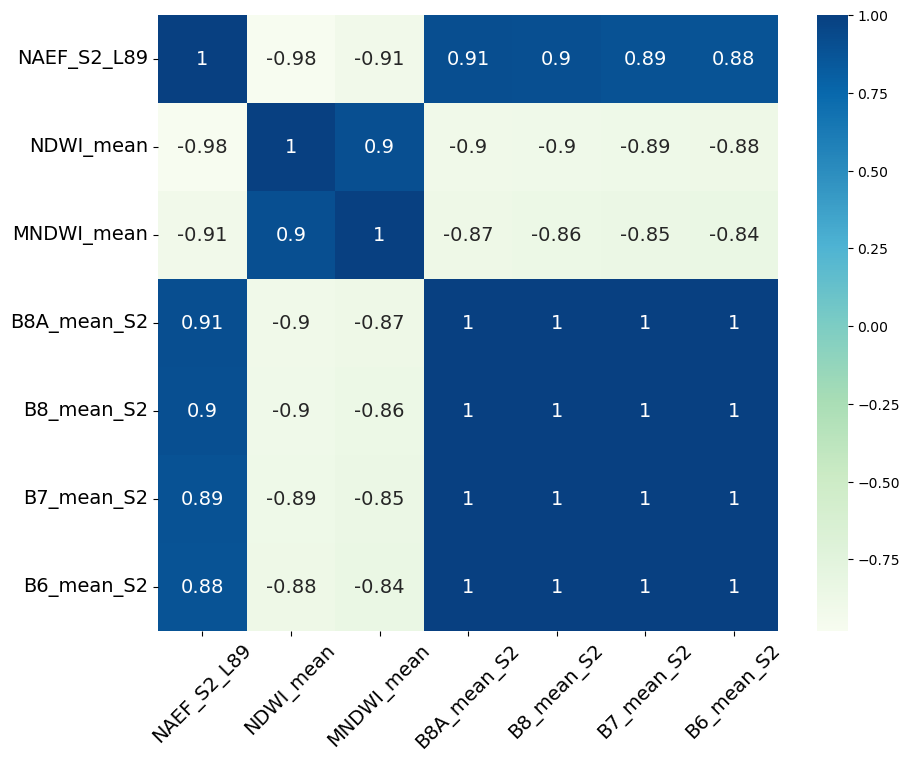

In [13]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.stats.outliers_influence import variance_inflation_factor
band_list2 = ["Freq", "mean_RE4", "mean_MNDWI","mean_NDWI","mean_NIR", "mean_RE1", "mean_RE2", "mean_RE3"]
band_list2 = ["Freq","mean_NDWI","mean_RE4"]
# 示例：假设你已经有一个多光谱特征DataFrame（X），列为波段，行为样本
# 假设列名如下（请根据实际数据替换）
band_list2 = [
    "Freq", "mean_B1", "mean_Blue", "mean_Green", "mean_MNDWI",
    "mean_NDWI", "mean_NIR", "mean_RE1", "mean_RE2", "mean_RE3",
    "mean_RE4", "mean_Red", "mean_SWIR1", "mean_SWIR2",
    "min_MNDWI", "NDWI_min"
]

# 示例数据：200个样本，模拟有线性相关性
np.random.seed(42)
n_samples = 200
X_sim = df[band_list2]


# 构建 DataFrame
X_df = pd.DataFrame(X_sim, columns=band_list2)

# 计算 VIF
def calculate_vif(df):
    vif_df = pd.DataFrame()
    vif_df["Feature"] = df.columns
    vif_df["VIF"] = [variance_inflation_factor(df.values, i) for i in range(df.shape[1])]
    return vif_df.sort_values(by="VIF", ascending=False)

vif_result = calculate_vif(X_df)

# 显示 VIF 表格
print("\n--- VIF 结果 ---")
print(vif_result)

# 绘制 VIF 条形图
plt.figure(figsize=(12, 6))
sns.barplot(x="VIF", y="Feature", data=vif_result, palette="Blues_d")
plt.axvline(x=10, color='r', linestyle='--', label='VIF = 10 threshold')
plt.title("Variance Inflation Factor (VIF) for Multispectral Features", fontsize=14)
plt.xlabel("VIF Value")
plt.ylabel("Feature")
plt.legend()
plt.tight_layout()
plt.show()


KeyError: "None of [Index(['Freq', 'mean_B1', 'mean_Blue', 'mean_Green', 'mean_MNDWI', 'mean_NDWI',\n       'mean_NIR', 'mean_RE1', 'mean_RE2', 'mean_RE3', 'mean_RE4', 'mean_Red',\n       'mean_SWIR1', 'mean_SWIR2', 'min_MNDWI', 'NDWI_min'],\n      dtype='object')] are in the [columns]"

In [27]:
path = 'G:\FB_new7\Morecambe_new7\Morecambe_points2_.shp'
points = gpd.read_file(path)
points.columns

Index(['Id', 'ORIG_FID', 'Id_1', 'mean_NDWI', 'Freq', 'geometry'], dtype='object')

In [ ]:
path = 'G:\FB_new7\Morecambe_new7\Morecambe_points2_.shp'
points = gpd.read_file(path)
points.columns

In [ ]:
Henber_point_path = 'E:\FB_download9\FB_importance\Henber_2019_sample_points_final_new.shp'
Morecambe_point_path = 'E:\FB_download9\FB_importance\Morecambe_2023_sample_points_final_new.shp'
Ribble_point_path = 'E:\FB_download9\FB_importance\Ribble1_2021_sample_points_final_new.shp'
Dee_point_path = 'E:\FB_download9\FB_importance\Ribble_2019_sample_points_new.shp'
Severn_point_path = 'E:\FB_download9\FB_importance\Severn_2020_sample_points_new.shp'
Solway_point_path = 'E:\FB_download9\FB_importance\Solway_2023_sample_points_final_new.shp'
Thames_point_path= 'E:\FB_download9\FB_importance\Thames1_2019_sample_points_final_new.shp'
Wash_point_path = 'E:\FB_download9\FB_importance\wash_bay_2022_sample_points_final_new.shp'

point_list = [Morecambe_point_path, Ribble_point_path, Dee_point_path, Severn_point_path, 
              Solway_point_path, Thames_point_path, Wash_point_path]

# path = Morecambe_point_path
# point = gpd.read_file(path)
# point.columns

Index(['Refer_dem', 'b1_FB', 'b2_FB', 'b3_FB', 'b4_FB', 'b5_FB', 'b6_FB',
       'b7_FB', 'b8_FB', 'b9_FB', 'b10_FB', 'b11_FB', 'b12_FB', 'b13_FB',
       'b14_FB', 'b15_FB', 'b16_FB', 'b17_FB', 'b18_FB', 'b19_FB', 'b20_FB',
       'b21_FB', 'b22_FB', 'b23_FB', 'b24_FB', 'b25_FB', 'b26_FB', 'b27_FB',
       'b28_FB', 'geometry'],
      dtype='object')

In [18]:
for i in range(len(point_list)):
    
    path = point_list[i] 
    out_path = path.replace('.shp', '_new.shp')
    
    point = gpd.read_file(path)
    point_ = point[['Refer_dem', 'geometry']]
    point_.to_file(out_path)


In [61]:
band_names = ['NEF_S2_L89', 'NEF_S2', 'NEF_L89', 
                  'B1_mean_S2', 'B2_mean_S2', 'B3_mean_S2', 'B4_mean_S2', 'B5_mean_S2', 'B6_mean_S2',
                  'B7_mean_S2', 'B8_mean_S2', 'B8A_mean_S2',  'B11_mean_S2', 'B12_mean_S2',
                'NDWI_mean_S2', 'MNDWI_mean_S2', 'NDWI_min_S2', 'MNDWI_min_S2',
                'B1_mean_L89', 'B2_mean_L89','B3_mean_L89','B4_mean_L89','B5_mean_L89',
                'B5_mean_L89_', 'B6_mean_L89','B7_mean_L89',
                'NDWI_mean_L8', 'MNDWI_mean_L8']

In [62]:
for path in point_list:
    
    point = gpd.read_file(path)
    
    rename_dict = {f"b{i}_FB": band_names[i-1] for i in range(1, 29)}
    point = point.rename(columns=rename_dict)
    
    SR_list = ['B1_mean_S2', 'B2_mean_S2', 'B3_mean_S2', 'B4_mean_S2', 'B5_mean_S2', 'B6_mean_S2','B7_mean_S2', 'B8_mean_S2', 'B8A_mean_S2',  'B11_mean_S2', 'B12_mean_S2',
           'B1_mean_L89', 'B2_mean_L89','B3_mean_L89','B4_mean_L89','B5_mean_L89','B5_mean_L89_', 'B6_mean_L89','B7_mean_L89']
    point[SR_list] = point[SR_list]/10000
    
    point.to_file(path)

C:\Users\minyu\AppData\Local\Temp\ipykernel_29084\26551941.py:12: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  point.to_file(path)
C:\Users\minyu\AppData\Local\Temp\ipykernel_29084\26551941.py:12: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  point.to_file(path)
C:\Users\minyu\AppData\Local\Temp\ipykernel_29084\26551941.py:12: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  point.to_file(path)
C:\Users\minyu\AppData\Local\Temp\ipykernel_29084\26551941.py:12: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  point.to_file(path)
C:\Users\minyu\AppData\Local\Temp\ipykernel_29084\26551941.py:12: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  point.to_file(path)
C:\Users\minyu\AppData\Local\Temp\ipykernel_29084\26551941.p

In [51]:
Henber_point_path = 'E:\FB_download9\FB_importance\Henber_2019_sample_points_final_new.shp'
k = gpd.read_file(Henber_point_path)
k.columns

Index(['Refer_dem', 'b1_FB', 'b2_FB', 'b3_FB', 'b4_FB', 'b5_FB', 'b6_FB',
       'b7_FB', 'b8_FB', 'b9_FB', 'b10_FB', 'b11_FB', 'b12_FB', 'b13_FB',
       'b14_FB', 'b15_FB', 'b16_FB', 'b17_FB', 'b18_FB', 'b19_FB', 'b20_FB',
       'b21_FB', 'b22_FB', 'b23_FB', 'b24_FB', 'b25_FB', 'b26_FB', 'b27_FB',
       'b28_FB', 'geometry'],
      dtype='object')

In [ ]:
# 假设原始是 band1, band2, ... band28
rename_dict = {f"b{i}_FB": band_names[i-1] for i in range(1, 29)}
rename_dict
k = k.rename(columns=rename_dict)


In [53]:
SR_list = ['B1_mean_S2', 'B2_mean_S2', 'B3_mean_S2', 'B4_mean_S2', 'B5_mean_S2', 'B6_mean_S2','B7_mean_S2', 'B8_mean_S2', 'B8A_mean_S2',  'B11_mean_S2', 'B12_mean_S2',
           'B1_mean_L89', 'B2_mean_L89','B3_mean_L89','B4_mean_L89','B5_mean_L89','B5_mean_L89_', 'B6_mean_L89','B7_mean_L89']
k[SR_list] = k[SR_list]/10000

In [ ]:
import os

year_list = [2019, 2020, 2021, 2022, 2023]
#'Region3','Region4',
region_list = ['Region1', 'Region2',  'Region5', 'Region6']
k = 0
for year in year_list:
    for region in region_list:
        folder_path = f'G:\ICESat-2\{region}\{region}_{year}\ATL08_{region}_{year}'

        # 列出文件夹中所有文件，筛选 .h5 文件
        h5_files = [f for f in os.listdir(folder_path) if f.endswith('.h5')]

        # 文件数量
        print(f"Number of .h5 files: {len(h5_files)}")
        k += len(h5_files)
print(k)

Number of .h5 files: 50
Number of .h5 files: 38
Number of .h5 files: 96
Number of .h5 files: 73
Number of .h5 files: 55
Number of .h5 files: 34
Number of .h5 files: 90
Number of .h5 files: 72
Number of .h5 files: 53
Number of .h5 files: 33
Number of .h5 files: 92
Number of .h5 files: 68
Number of .h5 files: 51
Number of .h5 files: 33
Number of .h5 files: 92
Number of .h5 files: 97
Number of .h5 files: 52
Number of .h5 files: 34
Number of .h5 files: 93
Number of .h5 files: 71
1277


In [39]:
import os

year_list = [2019, 2020, 2021, 2022, 2023]
region_list = ['Region1', 'Region2', 'Region5', 'Region6']

# 用集合存储所有唯一文件名
unique_h5_files = set()

for year in year_list:
    for region in region_list:
        folder_path = f'G:\ICESat-2\{region}\{region}_{year}\ATL08_{region}_{year}'
        #folder_path = f'H:\Paper4_data_copy\{region}\{region}_{year}\ATL08_{region}_{year}'

        # 列出文件夹中所有 .h5 文件
        h5_files = [f for f in os.listdir(folder_path) if f.endswith('.h5')]

        # 加入集合，自动去重
        unique_h5_files.update(h5_files)

        print(f"{region} {year}: {len(h5_files)} files, {len(set(h5_files))} unique")

print(f"Total number of unique .h5 files across all regions and years: {len(unique_h5_files)}")

len(unique_h5_files)

Region1 2019: 50 files, 50 unique
Region2 2019: 38 files, 38 unique
Region5 2019: 96 files, 96 unique
Region6 2019: 73 files, 73 unique
Region1 2020: 55 files, 55 unique
Region2 2020: 34 files, 34 unique
Region5 2020: 90 files, 90 unique
Region6 2020: 72 files, 72 unique
Region1 2021: 53 files, 53 unique
Region2 2021: 33 files, 33 unique
Region5 2021: 92 files, 92 unique
Region6 2021: 68 files, 68 unique
Region1 2022: 51 files, 51 unique
Region2 2022: 33 files, 33 unique
Region5 2022: 92 files, 92 unique
Region6 2022: 97 files, 97 unique
Region1 2023: 52 files, 52 unique
Region2 2023: 34 files, 34 unique
Region5 2023: 93 files, 93 unique
Region6 2023: 71 files, 71 unique
Total number of unique .h5 files across all regions and years: 942


942

In [40]:
import os

year_list = [2019, 2020, 2021, 2022, 2023]
region_list = ['Region3']

# 用集合存储所有唯一文件名
# unique_h5_files = set()

for year in year_list:
    for region in region_list:
        
        folder_path = f'H:\Paper4_data_copy\{region}\{region}_{year}\ATL08_{region}_{year}'

        # 列出文件夹中所有 .h5 文件
        h5_files = [f for f in os.listdir(folder_path) if f.endswith('.h5')]

        # 加入集合，自动去重
        unique_h5_files.update(h5_files)

        print(f"{region} {year}: {len(h5_files)} files, {len(set(h5_files))} unique")

print(f"Total number of unique .h5 files across all regions and years: {len(unique_h5_files)}")

len(unique_h5_files)

Region3 2019: 81 files, 81 unique
Region3 2020: 83 files, 83 unique
Region3 2021: 84 files, 84 unique
Region3 2022: 81 files, 81 unique
Region3 2023: 86 files, 86 unique
Total number of unique .h5 files across all regions and years: 1312


1312

In [41]:
import os

year_list = [2024]
region_list = ['Region1','Region2', 'Region3', 'Region4' ,'Region5' ,'Region6']

# 用集合存储所有唯一文件名
# unique_h5_files = set()

for year in year_list:
    for region in region_list:
        
        folder_path = f'I:\ICESat-2\{region}\{region}_{year}\ATL08_{region}_{year}'

        # 列出文件夹中所有 .h5 文件
        h5_files = [f for f in os.listdir(folder_path) if f.endswith('.h5')]

        # 加入集合，自动去重
        unique_h5_files.update(h5_files)

        print(f"{region} {year}: {len(h5_files)} files, {len(set(h5_files))} unique")

print(f"Total number of unique .h5 files across all regions and years: {len(unique_h5_files)}")

len(unique_h5_files)

Region1 2024: 41 files, 41 unique
Region2 2024: 42 files, 42 unique
Region3 2024: 74 files, 74 unique
Region4 2024: 86 files, 86 unique
Region5 2024: 71 files, 71 unique
Region6 2024: 75 files, 75 unique
Total number of unique .h5 files across all regions and years: 1554


1554

In [42]:
path = 'I:\ICESAT_name.txt'
with open(path, 'w', encoding='utf-8') as f:
    
    for name in  sorted(unique_h5_files):
        f.write(name + '\n')
